In [1]:
import yfinance as yf
import datetime as dt
import numpy as np 
import matplotlib.pyplot as plt

In [2]:
tickers = ['SPY', '^VIX']
start = dt.datetime(1994, 1, 1)
end = dt.datetime.now()

In [3]:
df = yf.download(tickers, start=start, end=end)

YF.download() has changed argument auto_adjust default to True


[*********************100%***********************]  2 of 2 completed


In [4]:
df = df['Close']


In [5]:
df['SPY lr'] = np.log(df['SPY'] / df['SPY'].shift(1))

In [6]:
df = df.dropna(subset=['SPY lr'])

In [7]:
df['past_rv'] = df['SPY lr'].rolling(21).std() * np.sqrt(252) * 100

In [8]:
df['future_rv'] = df['past_rv'].shift(-21)
df['premium'] = df['^VIX'] - df['future_rv']

In [9]:
df.head()

Ticker,SPY,^VIX,SPY lr,past_rv,future_rv,premium
Date,,,,,,
1994-01-04,26.183455,11.91,0.004026,NaN,7.250345,4.659655
1994-01-05,26.236071,10.94,0.002008,NaN,7.555844,3.384156
1994-01-06,26.236071,11.27,0.000000,NaN,11.328304,-0.058303
1994-01-07,26.393923,10.96,0.005999,NaN,11.250843,-0.290842
1994-01-10,26.709587,10.74,0.011889,NaN,10.417202,0.322798


In [10]:
print(df['past_rv'].isna().sum())

20


In [11]:
print(df['premium'].mean())
print(df['premium'].median())
print((df['premium'] > 0).mean() * 100)
print(df['premium'].min(), df['premium'].idxmin())

3.6611599483569397
4.413537675607877
82.68230741323013
-66.53210843888635 2020-02-19 00:00:00


In [12]:
df.loc['2020-02-19', ['^VIX', 'future_rv']]

Ticker
^VIX         14.380000
future_rv    80.912109
Name: 2020-02-19 00:00:00, dtype: float64

In [13]:
df['premium'].skew()

-3.1775156584006568

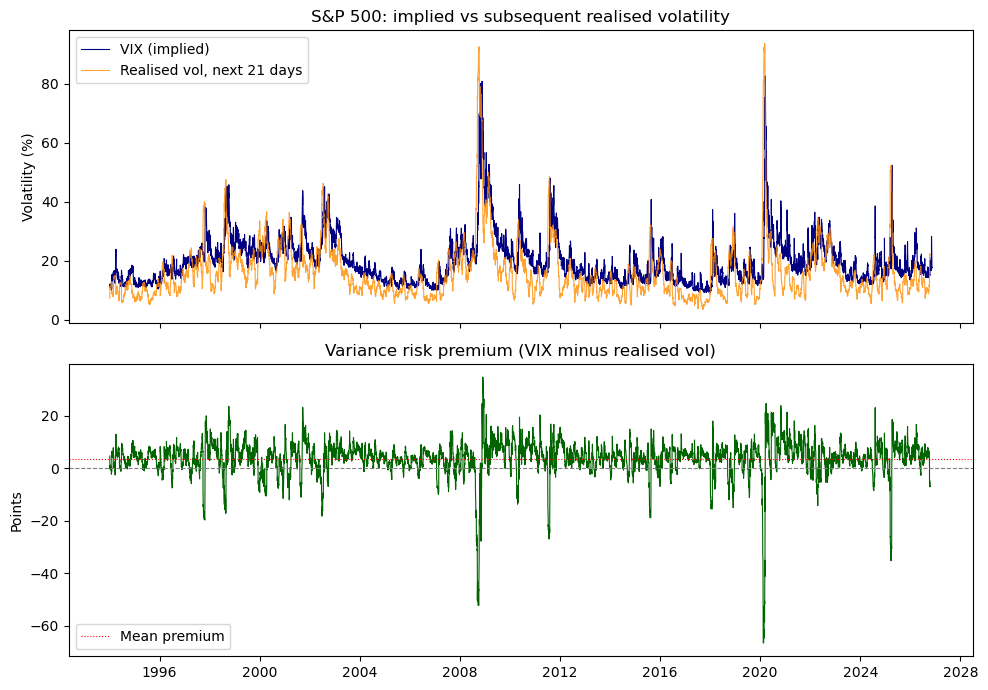

In [15]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

# --- Top: VIX vs future realised vol ---
ax1.plot(df['^VIX'], color='navy', linewidth=0.8, label='VIX (implied)')
ax1.plot(df['future_rv'], color='darkorange', linewidth=0.8, alpha=0.8, label='Realised vol, next 21 days')
ax1.set_title('S&P 500: implied vs subsequent realised volatility')
ax1.set_ylabel('Volatility (%)')
ax1.legend(loc='upper left')

# --- Bottom: premium ---
ax2.plot(df['premium'], color='darkgreen', linewidth=0.8)
ax2.axhline(0, color='grey', linestyle='--', linewidth=0.8)
ax2.axhline(df['premium'].mean(), color='red', linestyle=':', linewidth=0.8, label='Mean premium')
ax2.set_title('Variance risk premium (VIX minus realised vol)')
ax2.set_ylabel('Points')
ax2.legend(loc='lower left')

# TODO: annotate the worst day (optional, see below)

plt.tight_layout()
plt.savefig('vrp_chart.png', dpi=300)
plt.show()

In [16]:
import pandas as pd

In [17]:
bins = [0, 15, 20, 30, np.inf]
labels = ['<15', '15-20', '20-30', '30+']

df['vix_bucket'] = pd.cut(df['^VIX'], bins=bins, labels=labels)

In [18]:
print(df['vix_bucket'].value_counts())

vix_bucket
<15      2593
15-20    2489
20-30    2484
30+       703
Name: count, dtype: int64


In [22]:
summary = df.groupby('vix_bucket', observed=True)['premium'].agg(
    mean='mean',
    median='median',
    worst='min',
    days='count',
    pct_positive=lambda x: (x > 0).mean() * 100,
)
print(summary)

                mean    median      worst  days  pct_positive
vix_bucket                                                   
<15         2.451979  3.294988 -66.532108  2593     82.992673
15-20       3.758342  4.694958 -65.778880  2472     84.531941
20-30       4.235392  5.510985 -64.647221  2480     79.991948
30+         5.753730  8.356955 -58.558306   703     84.495021


In [53]:
summary['worst_to_mean'] = summary['worst'].abs() / summary['mean']
summary['worst_to_mean_label'] = summary['worst_to_mean'].map(lambda v: f'×{v:.0f}')

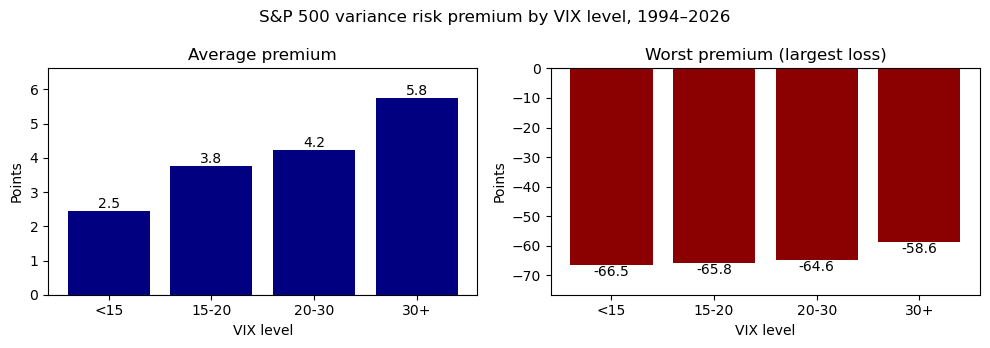

In [54]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))

fig.suptitle('S&P 500 variance risk premium by VIX level, 1994–2026', fontsize=12)
ax1.bar(summary.index, summary['mean'], color='navy')
ax1.set_title('Average premium')
ax1.set_ylabel('Points')

ax2.bar(summary.index, summary['worst'], color='darkred')
ax2.set_title('Worst premium (largest loss)')
ax2.set_ylabel('Points')

ax1.bar_label(ax1.containers[0], fmt='%.1f')
ax2.bar_label(ax2.containers[0], fmt='%.1f')

ax1.margins(y=0.15)
ax2.margins(y=0.15)

for ax in (ax1, ax2):
    ax.set_xlabel('VIX level')
    ax.axhline(0, color='grey', linewidth=0.8)

plt.tight_layout()
plt.savefig('vrp_by_vix.png', dpi=300)
plt.show()

Text(0.5, 0, 'VIX level')

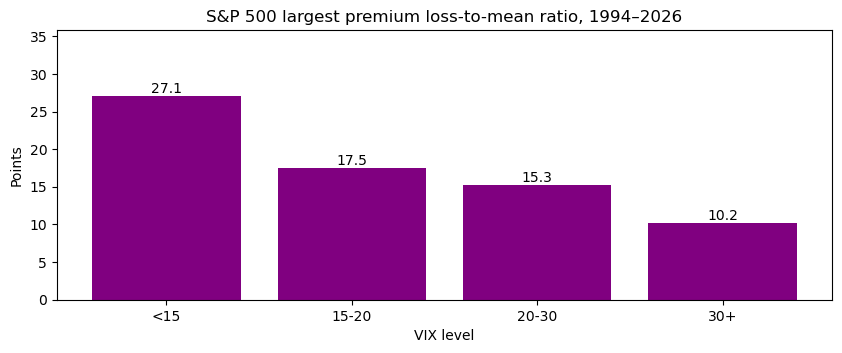

In [57]:
fig, (ax1) = plt.subplots(1, figsize=(10, 3.5))


ax1.set_title('S&P 500 largest premium loss-to-mean ratio, 1994–2026', fontsize=12)
ax1.bar(summary.index, summary['worst_to_mean'], color='purple')
ax1.set_ylabel('Points')
ax1.bar_label(ax1.containers[0], fmt='%.1f')
ax1.margins(y=0.32)
    
ax1.set_xlabel('VIX level')